# Task 21 – Feature Importance Analysis

## 1. Import libraries and load the dataset

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

working_directory = Path.cwd().resolve()
notebook_path = globals().get("__vsc_ipynb_file__")
dataset_candidates = [
    working_directory / "breast_cancer.csv",
    working_directory / "Task21" / "breast_cancer.csv",
    *(parent / "Task21" / "breast_cancer.csv" for parent in working_directory.parents),
]
if notebook_path:
    dataset_candidates.insert(0, Path(notebook_path).resolve().parent / "breast_cancer.csv")
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)

if dataset_path is None:
    raise FileNotFoundError(
        f"Could not find breast_cancer.csv. Current working directory: "
        f"{working_directory}. Checked: {', '.join(map(str, dataset_candidates))}"
    )

data = pd.read_csv(dataset_path)
target_column = "diagnosis"
X = data.drop(columns=target_column)
y = data[target_column]

print(f"Dataset: {dataset_path}")
print(f"Rows: {len(data)} | Features: {X.shape[1]}")
print("\nDiagnosis counts:")
print(y.value_counts())
data.head()

Dataset: C:\Users\USER\OneDrive\Desktop\veda\AI-ML-Internship-Tasks\Task21\breast_cancer.csv
Rows: 569 | Features: 30

Diagnosis counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


## 2. Split the data and train a tree-based model

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")
print("\nClassification report:")
print(classification_report(y_test, predictions, zero_division=0))

Test accuracy: 0.965

Classification report:
              precision    recall  f1-score   support

      benign       0.95      1.00      0.97        72
   malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## 3. Create and display the feature importance table

In [7]:
importance_table = (
    pd.DataFrame(
        {"feature": X.columns, "importance": model.feature_importances_}
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

importance_table.index = importance_table.index + 1
importance_table.index.name = "rank"
importance_table

,feature,importance
rank,,
1,worst perimeter,0.150188
2,worst area,0.135993
3,worst concave points,0.105086
4,mean concave points,0.101816
5,worst radius,0.068266
6,mean perimeter,0.057941
7,mean concavity,0.053002
8,mean radius,0.050573
9,worst concavity,0.039171


## 4. Visualize the most important features

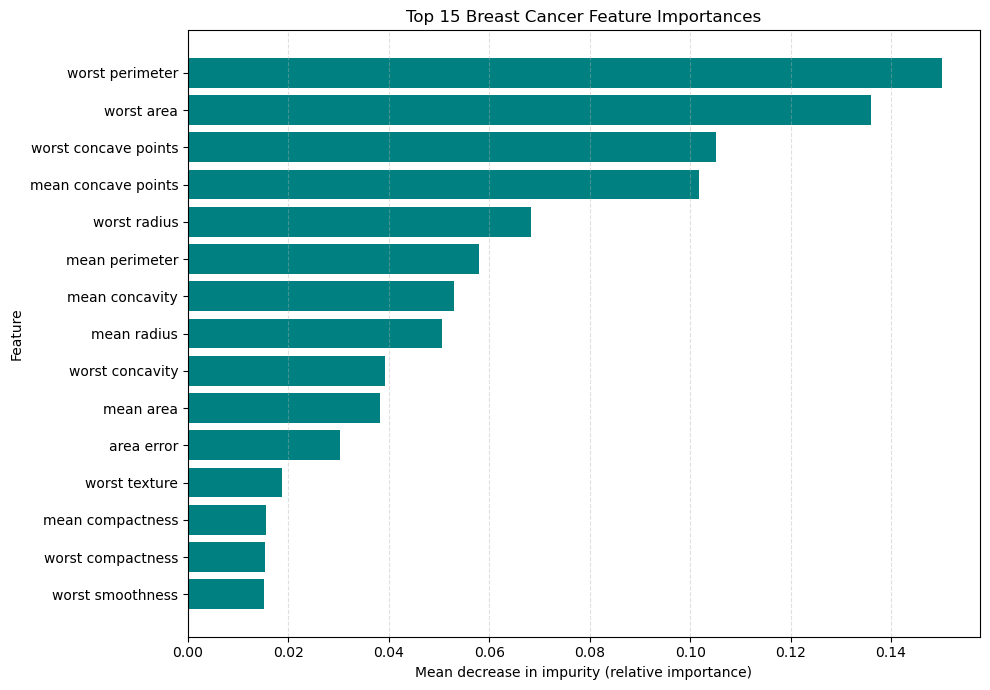

In [8]:
top_n = 15
top_features = importance_table.head(top_n).sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_features["feature"], top_features["importance"], color="teal")
ax.set_title(f"Top {top_n} Breast Cancer Feature Importances")
ax.set_xlabel("Mean decrease in impurity (relative importance)")
ax.set_ylabel("Feature")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Interpretation

In [9]:
print("Top five features in this fitted model:")
for row in importance_table.head(5).itertuples(index=False):
    print(f"- {row.feature}: {row.importance:.4f}")

print(
    "\nInterpretation: These features had the largest impurity-based "
    "importance values for distinguishing the diagnosis labels in this "
    "Random Forest. The scores are relative and do not imply causation."
)

Top five features in this fitted model:
- worst perimeter: 0.1502
- worst area: 0.1360
- worst concave points: 0.1051
- mean concave points: 0.1018
- worst radius: 0.0683

Interpretation: These features had the largest impurity-based importance values for distinguishing the diagnosis labels in this Random Forest. The scores are relative and do not imply causation.
